# Chapter 19: Attention, Information Avoidance, and Bounded Rationality

This notebook reruns four worked examples from the chapter: a vivid demo against verified breadth, a satisficing hire, a retirement alert left unopened, and a contest that concentrates attention. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def weighted_score(weights, attributes):
    """Weighted score Q = sum_i w_i x_i (attention-economics-demo-effect).

    Book (ch019): Q_A = 0.6(55) + 0.4(95) = 71; Q_B = 0.6(68) + 0.4(55) = 62.8;
    with w = 0.9: 59 and 66.7.
    """
    return float(sum(float(w) * float(x) for w, x in zip(weights, attributes)))


def satisfice(scores, aspiration, cost, value_per_point=1.0):
    """Sequential satisficing search (bounded-rationality-and-satisficing).

    Stops at tau = min{t: score_t >= aspiration}. Returns tau (1-based, None if no
    score clears), hired index, screening cost tau x cost, the extra cost of
    inspecting the remaining options, the gross gain of exhaustive review
    (max - hired) x value_per_point and its net. Book (ch019): scores 68, 77, 91, 82,
    A = 75, cost 300, 100 per point: tau 2, screening 600, gain 1,400, net 800.
    """
    scores = [float(x) for x in scores]
    n = len(scores)
    tau = next((i + 1 for i, x in enumerate(scores) if x >= aspiration), None)
    if tau is None:
        return {"tau": None, "hired": None, "screening_cost": n * float(cost), "extra_cost": 0.0,
                "gain": None, "net": None}
    hired = tau - 1
    extra = (n - tau) * float(cost)
    gain = (max(scores) - scores[hired]) * float(value_per_point)
    return {"tau": tau, "hired": hired, "screening_cost": tau * float(cost), "extra_cost": extra,
            "gain": gain, "net": gain - extra}


def attention_shares(weights, total=1.0):
    """Rank-weight attention shares alpha_j = w_j / sum w, times total
    (signaling-winner-take-attention). Book (ch019): weights 5, 1, 0.5 give 0.7692,
    0.1538 and 0.0769; with 1,000 buyers about 769, 154 and 77 inquiries.
    """
    s = float(sum(weights))
    return [float(total) * float(w) / s for w in weights]


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(weighted_score=weighted_score, satisfice=satisfice, attention_shares=attention_shares)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'attention-economics-demo-effect': {'A': {'breadth': 55, 'salience': 95},
                                     'B': {'breadth': 68, 'salience': 55},
                                     'w': 0.6,
                                     'Q_A': 71,
                                     'Q_B': 62.8,
                                     'w_2': 0.9,
                                     'Q_A_2': 59,
                                     'Q_B_2': 66.7},
 'bounded-rationality-and-satisficing': {'names': ['Lina', 'Omar', 'Priya', 'Chen'],
                                         'scores': [68, 77, 91, 82],
                                         'A': 75,
                                         'cost': 300,
                                         'per_point': 100,
                                         'tau': 2,
                                         'screening': 600,
                                         'gain': 1400,
                                         'extra': 600,
                                         'net': 800,
                                         'cost_2': 900,
                                         'extra_2': 1800,
                                         'A_2': 85,
                                         'tau_2': 3},
 'information-avoidance': {'p': 0.5,
                           'gain': 120,
                           'instrumental': 60,
                           'anxiety': 80,
                           'net': -20,
                           'anxiety_2': 30,
                           'net_2': 30},
 'signaling-winner-take-attention': {'weights': [5, 1, 0.5],
                                     'total': 6.5,
                                     'alphas': [0.7692, 0.1538, 0.0769],
                                     'buyers': 1000,
                                     'inquiries': [769, 154, 77],
                                     'benefit': 5,
                                     'cost_high': 2,
                                     'cost_weak': 8,
                                     'net_high': 3,
                                     'net_weak': -3,
                                     'cost_weak_2': 3},
 'constructed': {'attention-economics-demo-effect': {'w': [0.3, 0.75], 'salA': [75, 100]},
                 'bounded-rationality-and-satisficing': {'A': [65], 'cost': [600]},
                 'information-avoidance': {'p': [0.25, 0.75]},
                 'signaling-winner-take-attention': {'w1': [1, 2], 'weak': [5]}}}


def short(x):
    """Up to 2 decimals, trailing zeros removed: 71, 62.8, 0.75."""
    return f"{x:,.2f}".rstrip("0").rstrip(".")


def demo_score_picture(w=0.6, sal_a=95):
    bv = BV["attention-economics-demo-effect"]
    eA, eB, sB = bv["A"]["breadth"], bv["B"]["breadth"], bv["B"]["salience"]
    qa = behavioral.weighted_score([w, 1 - w], [eA, sal_a])
    qb = behavioral.weighted_score([w, 1 - w], [eB, sB])
    winner, tie = tie_or_winner("A", qa, "B", qb)
    w_star = (sal_a - sB) / ((sal_a - sB) + (eB - eA))
    ws = np.linspace(0, 1, 101)
    fig, ax = new_figure()
    ax.plot(ws, [behavioral.weighted_score([x, 1 - x], [eA, sal_a]) for x in ws], color=PALETTE["gold"], linewidth=2.2)
    ax.plot(ws, [behavioral.weighted_score([x, 1 - x], [eB, sB]) for x in ws], color=PALETTE["teal"], linewidth=2.2)
    label(ax, 0.02, sal_a, f"Q_A (demo project, salience {sal_a})", col="gold", dx=2, dy=4)
    label(ax, 0.02, sB, "Q_B (broad project)", col="teal", dx=2, dy=-6, va="top")
    vline(ax, w_star, f"tie at w = {num(w_star, 3)}", col="grey", ha="right" if w_star > 0.5 else "left", y_frac=0.12)
    side = {"dx": -8, "ha": "right"} if w > 0.7 else {"dx": 8}
    mark(ax, w, qa, f"Q_A = {short(qa)}", col="gold", **side, dy=8 if qa >= qb else -10, va="bottom" if qa >= qb else "top")
    mark(ax, w, qb, f"Q_B = {short(qb)}", col="teal", **side, dy=-10 if qa >= qb else 8, va="top" if qa >= qb else "bottom")
    ax.set_xlim(0, 1)
    ax.set_ylim(45, 108)
    ax.set_xlabel("Breadth weight w")
    ax.set_ylabel("Score Q")
    win_text = "Tie" if tie else f"Project {winner}"
    metrics = {"Q_A": short(qa), "Q_B": short(qb), "Winner": win_text, "Tie weight w*": num(w_star, 3)}
    if tie:
        verdict = "The scores tie, so the rule does not pick a project."
    else:
        verdict = (f"Project {winner} receives the budget"
                   + (" despite its lower verified breadth." if winner == "A" else ", the project with more verified breadth."))
    interp = (f"Q_A = {short(w)}(55) + {short(1 - w)}({sal_a}) = {short(w * eA)} + {short((1 - w) * sal_a)} = {short(qa)}, and "
              f"Q_B = {short(w)}(68) + {short(1 - w)}(55) = {short(w * eB)} + {short((1 - w) * sB)} = {short(qb)}. {verdict} "
              f"The scores tie at w = ({sal_a} - 55) / (({sal_a} - 55) + 13) = {num(w_star, 3)}; above that weight the broad "
              f"project wins.")
    steps = [f"Q_A = {short(w)} x 55 + {short(1 - w)} x {sal_a} = {short(w * eA)} + {short((1 - w) * sal_a)} = {short(qa)}",
             f"Q_B = {short(w)} x 68 + {short(1 - w)} x 55 = {short(w * eB)} + {short((1 - w) * sB)} = {short(qb)}",
             f"Winner: {win_text}",
             f"Tie: 55w + {sal_a}(1 - w) = 68w + 55(1 - w) gives w = {sal_a - sB} / {sal_a - sB + eB - eA} = {num(w_star, 3)}"]
    alt = (f"Two straight score lines against the breadth weight w. At w = {short(w)} project A scores {short(qa)} and "
           f"project B {short(qb)}; the lines cross at w = {num(w_star, 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def satisfice_picture(asp=75, cost=300):
    A = asp
    bv = BV["bounded-rationality-and-satisficing"]
    names, scores, per = bv["names"], bv["scores"], bv["per_point"]
    res = behavioral.satisfice(scores, A, cost, per)
    tau, h = res["tau"], res["hired"]
    best = int(np.argmax(scores))
    remaining = len(scores) - tau
    fig, ax = new_figure()
    cols = []
    for i in range(len(scores)):
        cols.append("gold" if i == h else ("teal" if i < tau else "grey"))
    bar_compare(ax, [f"{i + 1}. {n}" for i, n in enumerate(names)], scores, colors=cols,
                value_labels=[f"{s}" + ("" if i < tau else " (unseen)") for i, s in enumerate(scores)],
                ylabel="Score (0 to 100)", xlabel="Applicants in interview order")
    hline(ax, A, col="terracotta")
    ax.text(0.01, 0.97, f"dashed line: aspiration A = {A}", transform=ax.transAxes, ha="left", va="top", fontsize=10.5,
            color=PALETTE["terracotta"], bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.set_ylim(0, 125)
    ax.text(0.99, 0.97, f"stop at tau = {tau}: hire {names[h]}", transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, color=PALETTE["gold"],
            bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    net = res["net"]
    if net > 0:
        verdict = "exhaustive review would pay"
    elif net < 0:
        verdict = "stopping dominates exhaustive review"
    else:
        verdict = "exhaustive review and stopping tie"
    metrics = {"Stopping point tau": str(tau), "Hired": f"{names[h]} ({scores[h]})",
               "Screening cost": money(res["screening_cost"], 0), "Extra cost of exhaustive review": money(res["extra_cost"], 0),
               "Gain from exhaustive review": money(res["gain"], 0), "Net of exhaustive review": money(net, 0)}
    seen = ", ".join(f"{names[i]} {scores[i]}" for i in range(tau))
    gain_line = (f"({scores[best]} - {scores[h]}) x {money(per, 0)} = {money(res['gain'], 0)}")
    interp = (f"Interviewing in order ({seen}), the first score at or above {A} is {names[h]}'s {scores[h]}, so tau = {tau} "
              f"and screening costs {tau} x {money(cost, 0)} = {money(res['screening_cost'], 0)}. Exhaustive review "
              f"needs {remaining} more interview{'s' if remaining != 1 else ''} costing {remaining} x {money(cost, 0)} = "
              f"{money(res['extra_cost'], 0)} and gains {gain_line}. Net {money(res['gain'], 0)} - "
              f"{money(res['extra_cost'], 0)} = {money(net, 0)}, so {verdict}. In plain numbers: {remaining} x {cost} = "
              f"{num(res['extra_cost'], 0)} and {num(res['gain'], 0)} - {num(res['extra_cost'], 0)} = {num(net, 0)} dollars.")
    steps = [f"First score at or above {A}: {names[h]} ({scores[h]}), so tau = {tau}",
             f"Screening cost = {tau} x {money(cost, 0)} = {money(res['screening_cost'], 0)}",
             f"Extra interviews = {remaining} x {money(cost, 0)} = {money(res['extra_cost'], 0)}",
             f"Gain = {gain_line}",
             f"Net = {money(res['gain'], 0)} - {money(res['extra_cost'], 0)} = {money(net, 0)}"]
    alt = (f"Bars for four applicants in interview order with an aspiration line at {A}. The manager stops at "
           f"applicant {tau}, {names[h]}, scoring {scores[h]}; later applicants are unseen. Exhaustive review would net "
           f"{money(net, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def alert_net(p, gain, anxiety):
    """Instrumental value p x gain and net value of opening the alert (information-avoidance)."""
    inst = p * gain
    return inst, inst - anxiety


def avoidance_picture(anx=80, p=0.5):
    gain = BV["information-avoidance"]["gain"]
    inst, net = alert_net(p, gain, anx)
    if net > 0:
        decision = "Open the alert"
    elif net < 0:
        decision = "Avoid the alert"
    else:
        decision = "Indifferent (net value exactly zero)"
    fig, ax = new_figure()
    bar_compare(ax, ["Instrumental value", "Anxiety cost", "Net value"], [inst, -anx, net],
                colors=["teal", "terracotta", "gold" if net >= 0 else "navy"],
                value_labels=[money(inst, 0), money(-anx, 0), money(net, 0)], ylabel="Value ($)", xlabel="Component")
    ax.set_ylim(-95, 135)
    ax.text(0.99, 0.97, decision, transform=ax.transAxes, ha="right", va="top", fontsize=10.5, color=PALETTE["ink"],
            bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    p_star = anx / gain
    metrics = {"Instrumental value": money(inst, 0), "Anxiety cost": money(anx, 0), "Net value": money(net, 0),
               "Decision": decision, "Break-even probability": num(p_star, 3)}
    if net == 0:
        why = "She is exactly indifferent between opening and avoiding."
    elif net > 0:
        why = "She opens it."
    else:
        why = "She avoids it, even though the signal is useful."
    interp = (f"Instrumental value = {short(p)} x $120 = {money(inst, 0)}. Net value = {money(inst, 0)} - {money(anx, 0)} = "
              f"{money(net, 0)}. In plain numbers: {short(p)} x 120 = {num(inst, 0)} and {num(inst, 0)} - {anx} = "
              f"{num(net, 0)} dollars. {why} Opening pays only when 120p exceeds {anx}, that is p above {num(p_star, 3)}.")
    steps = [f"Instrumental value = {short(p)} x $120 = {money(inst, 0)}",
             f"Net value = {money(inst, 0)} - {money(anx, 0)} = {money(net, 0)}",
             f"Decision: {decision}",
             f"Break-even p = {anx} / 120 = {num(p_star, 3)}"]
    alt = (f"Bars for instrumental value {money(inst, 0)}, anxiety cost {money(anx, 0)} shown below zero, and net value "
           f"{money(net, 0)}. Decision: {decision}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def entry_nets(benefit, cost_high, cost_weak):
    """Net entry benefits and the outcome (signaling-winner-take-attention)."""
    nh, nw = benefit - cost_high, benefit - cost_weak
    if nh > 0 > nw:
        outcome = "Separating"
    elif nh > 0 and nw == 0:
        outcome = "Weak type indifferent: separation not strict"
    elif nh > 0 and nw > 0:
        outcome = "Pooling"
    else:
        outcome = "No high-type entry"
    return nh, nw, outcome


def attention_picture(w1=5, weak=8):
    bv = BV["signaling-winner-take-attention"]
    weights = [w1, 1, 0.5]
    total = sum(weights)
    inq = behavioral.attention_shares(weights, bv["buyers"])
    nh, nw, outcome = entry_nets(bv["benefit"], bv["cost_high"], weak)
    fig, (ax, ax2) = new_figure(ncols=2)
    bar_compare(ax, ["A (95)", "B (92)", "C (88)"], inq, colors=["gold", "teal", "navy"],
                value_labels=[num(x, 0) for x in inq], ylabel="Expected inquiries", xlabel="Vendor (reliability)")
    ax.set_ylim(0, 1000)
    bar_compare(ax2, ["High type", "Weak type"], [nh, nw], colors=["teal", "terracotta"],
                value_labels=[f"{num(nh, 0)}", f"{num(nw, 0)}"], ylabel="Net entry benefit ($ million)", xlabel="Type")
    ax2.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax2.set_ylim(-4.5, 4.5)
    ax2.set_title(outcome if len(outcome) < 30 else "Weak type indifferent", fontsize=11)
    metrics = {"Inquiries A, B, C": f"{num(inq[0], 0)}, {num(inq[1], 0)}, {num(inq[2], 0)}",
               "Share of A": num(inq[0] / bv["buyers"], 4), "High-type net ($ million)": num(nh, 0),
               "Weak-type net ($ million)": num(nw, 0), "Outcome": outcome}
    if nw == 0:
        tail = ("The weak type nets exactly zero: it is indifferent between entering and staying out, so entry "
                "separates the types only weakly, not strictly.")
    elif nw < 0:
        tail = "Only the high type gains from entry, so entry separates the types."
    else:
        tail = "Both types gain from entry, so participation pools them and entry alone says nothing about type."
    interp = (f"Total weight is {short(w1)} + 1 + 0.5 = {short(total)}, so A's share is {short(w1)} / {short(total)} = "
              f"{num(inq[0] / 1000, 4)} and A expects about {num(inq[0], 0)} of 1,000 inquiries (B {num(inq[1], 0)}, "
              f"C {num(inq[2], 0)}). Entry nets are $5 - $2 = ${num(nh, 0)} million for the high type and $5 - ${weak} = "
              f"{'-' if nw < 0 else ''}${num(abs(nw), 0)} million for the weak type. {tail}")
    steps = [f"Total weight = {short(w1)} + 1 + 0.5 = {short(total)}",
             f"A: {short(w1)} / {short(total)} x 1,000 = {num(inq[0], 1)}",
             f"B: 1 / {short(total)} x 1,000 = {num(inq[1], 1)}; C: 0.5 / {short(total)} x 1,000 = {num(inq[2], 1)}",
             f"High type: 5 - 2 = {num(nh, 0)}",
             f"Weak type: 5 - {weak} = {num(nw, 0)}",
             f"Outcome: {outcome}"]
    alt = (f"Left: expected inquiries of about {num(inq[0], 0)}, {num(inq[1], 0)} and {num(inq[2], 0)} for vendors A, B "
           f"and C with first-rank weight {short(w1)}. Right: net entry benefit {num(nh, 0)} for the high type and "
           f"{num(nw, 0)} for the weak type. {outcome}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Attention economics and the demo effect

The committee scores each project as $Q_j=wE_j+(1-w)S_j$, with breadth $E$ and salience $S$. Project A has breadth 55 and salience 95; project B has breadth 68 and salience 55.

$$Q_A=0.6(55)+0.4(95)=71, \qquad Q_B=0.6(68)+0.4(55)=62.8$$

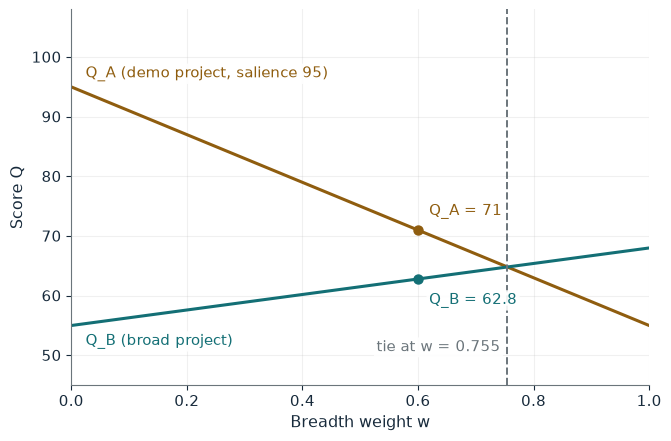

Q_A            71
Q_B            62.8
Winner         Project A
Tie weight w*  0.755

Worked steps:
  1. Q_A = 0.6 x 55 + 0.4 x 95 = 33 + 38 = 71
  2. Q_B = 0.6 x 68 + 0.4 x 55 = 40.8 + 22 = 62.8
  3. Winner: Project A
  4. Tie: 55w + 95(1 - w) = 68w + 55(1 - w) gives w = 40 / 53 = 0.755

Q_A = 0.6(55) + 0.4(95) = 33 + 38 = 71, and Q_B = 0.6(68) + 0.4(55) = 40.8 + 22 = 62.8. Project A receives the budget despite its lower verified breadth. The scores tie at w = (95 - 55) / ((95 - 55) + 13) = 0.755; above that weight the broad project wins.


In [2]:
show(demo_score_picture(w=0.6, sal_a=95))

Change one input, `w`, and hold the others at the book's values:

In [3]:
sweep(demo_score_picture, 'w', [0.3, 0.6, 0.75, 0.9], {'sal_a': 95}, ['Q_A', 'Q_B', 'Winner'])

w | Q_A | Q_B | Winner
0.3 | 83 | 58.9 | Project A
0.6 | 71 | 62.8 | Project A
0.75 | 65 | 64.75 | Project A
0.9 | 59 | 66.7 | Project B


At $w=0.6$ the demo project wins, 71 to 62.8. At $w=0.9$ the ranking reverses, 59 to 66.7, with no change in the underlying scores. The lines cross at $w=40/53=0.755$.

## 2. Bounded rationality and satisficing

Applicants arrive as Lina 68, Omar 77, Priya 91, Chen 82. With aspiration 75 the search stops at $\tau=2$, and exhaustive review would gain

$$(91-77)(\$100)=\$1{,}400.$$

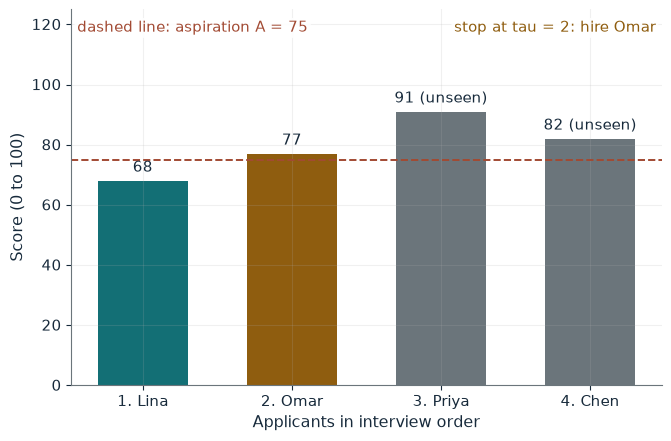

Stopping point tau               2
Hired                            Omar (77)
Screening cost                   $600
Extra cost of exhaustive review  $600
Gain from exhaustive review      $1,400
Net of exhaustive review         $800

Worked steps:
  1. First score at or above 75: Omar (77), so tau = 2
  2. Screening cost = 2 x $300 = $600
  3. Extra interviews = 2 x $300 = $600
  4. Gain = (91 - 77) x $100 = $1,400
  5. Net = $1,400 - $600 = $800

Interviewing in order (Lina 68, Omar 77), the first score at or above 75 is Omar's 77, so tau = 2 and screening costs 2 x $300 = $600. Exhaustive review needs 2 more interviews costing 2 x $300 = $600 and gains (91 - 77) x $100 = $1,400. Net $1,400 - $600 = $800, so exhaustive review would pay. In plain numbers: 2 x 300 = 600 and 1,400 - 600 = 800 dollars.


In [4]:
show(satisfice_picture(asp=75, cost=300))

Change one input, `cost`, and hold the others at the book's values:

In [5]:
sweep(satisfice_picture, 'cost', [300, 600, 900], {'asp': 75}, ['Stopping point tau', 'Extra cost of exhaustive review', 'Net of exhaustive review'])

cost | Stopping point tau | Extra cost of exhaustive review | Net of exhaustive review
300 | 2 | $600 | $800
600 | 2 | $1,200 | $200
900 | 2 | $1,800 | -$400


With \$300 interviews, exhaustive review nets \$1,400 - \$600 = \$800. At \$900 the two extra interviews cost \$1,800, more than the gain, so stopping at Omar dominates.

## 3. Information avoidance

A free alert reveals a correctable \$120 shortfall with probability 0.5, so its instrumental value is $0.5(\$120)=\$60$. With expected anxiety of \$80 the net value is $\$60-\$80=-\$20$.

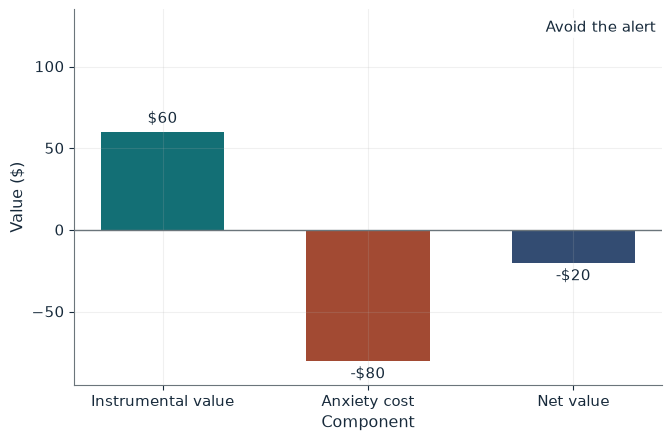

Instrumental value      $60
Anxiety cost            $80
Net value               -$20
Decision                Avoid the alert
Break-even probability  0.667

Worked steps:
  1. Instrumental value = 0.5 x $120 = $60
  2. Net value = $60 - $80 = -$20
  3. Decision: Avoid the alert
  4. Break-even p = 80 / 120 = 0.667

Instrumental value = 0.5 x $120 = $60. Net value = $60 - $80 = -$20. In plain numbers: 0.5 x 120 = 60 and 60 - 80 = -20 dollars. She avoids it, even though the signal is useful. Opening pays only when 120p exceeds 80, that is p above 0.667.


In [6]:
show(avoidance_picture(anx=80, p=0.5))

Change one input, `anx`, and hold the others at the book's values:

In [7]:
sweep(avoidance_picture, 'anx', [0, 30, 80], {'p': 0.5}, ['Instrumental value', 'Net value', 'Decision'])

anx | Instrumental value | Net value | Decision
0 | $60 | $60 | Open the alert
30 | $60 | $30 | Open the alert
80 | $60 | -$20 | Avoid the alert


The signal is useful in every case; only the cost of knowing changes. At probability 0.25 with anxiety \$30 the net is exactly zero, so she is indifferent.

## 4. Signaling and winner-take-attention markets

Rank weights 5, 1 and 0.5 split 1,000 inquiries: $\alpha_A=5/6.5\approx0.7692$. Entry nets $\$5-\$2=\$3>0$ for the high type and $\$5-\$8=-\$3<0$ for the weak type.

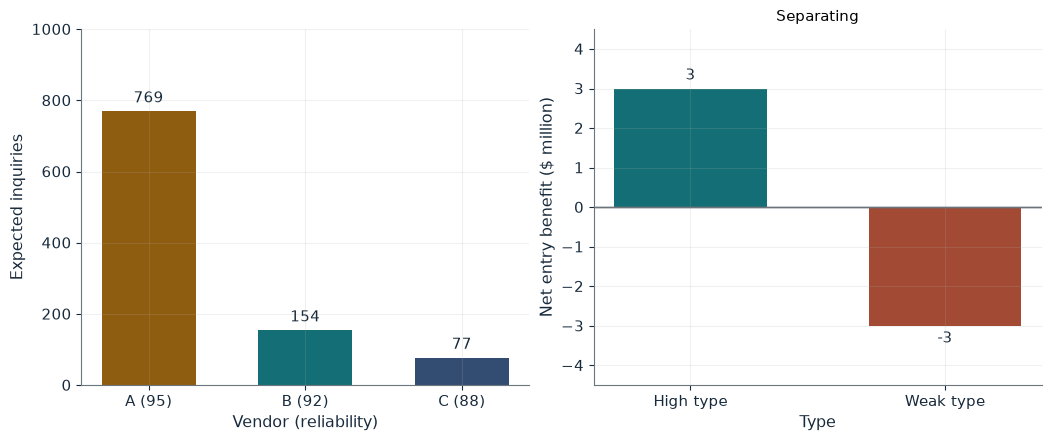

Inquiries A, B, C          769, 154, 77
Share of A                 0.7692
High-type net ($ million)  3
Weak-type net ($ million)  -3
Outcome                    Separating

Worked steps:
  1. Total weight = 5 + 1 + 0.5 = 6.5
  2. A: 5 / 6.5 x 1,000 = 769.2
  3. B: 1 / 6.5 x 1,000 = 153.8; C: 0.5 / 6.5 x 1,000 = 76.9
  4. High type: 5 - 2 = 3
  5. Weak type: 5 - 8 = -3
  6. Outcome: Separating

Total weight is 5 + 1 + 0.5 = 6.5, so A's share is 5 / 6.5 = 0.7692 and A expects about 769 of 1,000 inquiries (B 154, C 77). Entry nets are $5 - $2 = $3 million for the high type and $5 - $8 = -$3 million for the weak type. Only the high type gains from entry, so entry separates the types.


In [8]:
show(attention_picture(w1=5, weak=8))

Change one input, `weak`, and hold the others at the book's values:

In [9]:
sweep(attention_picture, 'weak', [3, 5, 8], {'w1': 5}, ['High-type net ($ million)', 'Weak-type net ($ million)', 'Outcome'])

weak | High-type net ($ million) | Weak-type net ($ million) | Outcome
3 | 3 | 2 | Pooling
5 | 3 | 0 | Weak type indifferent: separation not strict
8 | 3 | -3 | Separating


At a weak-type cost of \$8 million entry separates the types. At \$5 million the weak type nets exactly zero and is indifferent, so separation is not strict; at \$3 million both enter and pool.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

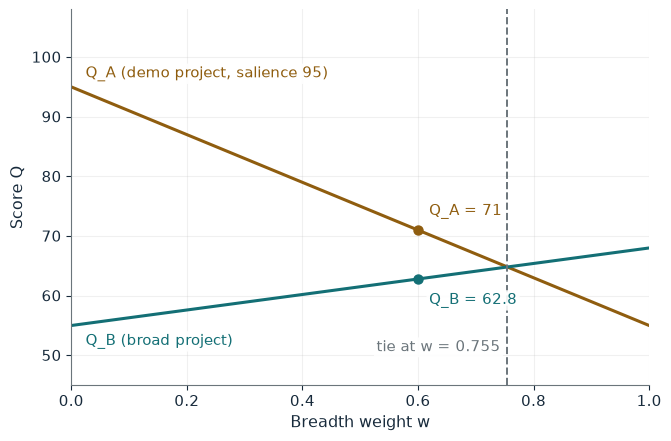

Q_A            71
Q_B            62.8
Winner         Project A
Tie weight w*  0.755

Worked steps:
  1. Q_A = 0.6 x 55 + 0.4 x 95 = 33 + 38 = 71
  2. Q_B = 0.6 x 68 + 0.4 x 55 = 40.8 + 22 = 62.8
  3. Winner: Project A
  4. Tie: 55w + 95(1 - w) = 68w + 55(1 - w) gives w = 40 / 53 = 0.755

Q_A = 0.6(55) + 0.4(95) = 33 + 38 = 71, and Q_B = 0.6(68) + 0.4(55) = 40.8 + 22 = 62.8. Project A receives the budget despite its lower verified breadth. The scores tie at w = (95 - 55) / ((95 - 55) + 13) = 0.755; above that weight the broad project wins.


In [10]:
show(demo_score_picture(w=0.6, sal_a=95))

## Practice

**1.** With the book's scores, at what breadth weight do the two projects tie?

<details><summary>Answer</summary>

55w + 95(1 - w) = 68w + 55(1 - w) gives 95 - 40w = 55 + 13w, so w = 40/53 = 0.755.

</details>

**2.** With \$600 per interview and aspiration 75, is exhaustive review worth it?

<details><summary>Answer</summary>

Two more interviews cost 2 x 600 = 1,200 against a gain of 1,400, so the net is 200 > 0: yes, barely.

</details>

**3.** With first-rank weight 2, how many of 1,000 inquiries does vendor A get?

<details><summary>Answer</summary>

2 / (2 + 1 + 0.5) x 1,000 = 571.4, about 571.

</details>